# L2A validation: remote-sensing reflectance against HYPERNETS

This notebook evaluates the remote-sensing reflectance $R_{rs}$ retrieved from Sentinel-2 by GRS (L2A products)
against the measurements of the [HYPERNETS](https://www.hypernets.eu) (WATERHYPERNET) autonomous hyperspectral
radiometers of two French sites: `BEFR`, in the Berre lagoon, and `MAFR`, in the Gironde estuary.

It follows the chain of the validation with AERONET-OC ({doc}`../aeronet_oc_validation`), with
{mod}`grstbx.validation`: GRS runs on **Sentinel-2 subsets of 5 km x 5 km centred on the station**, not on
the full tiles, and the matchups are made in the same table format, with the same quality criteria, statistics
and dashboard.

**Workflow**

1. HYPERNETS measurements of the in situ validation database ({func}`~grstbx.validation.read_hypernets`);
2. normalization of the in situ $R_{rs}$, measured at oblique viewing, to nadir viewing;
3. Sentinel-2 L1C subsets of 251 x 251 pixels at 20 m centred on the station, for the images with a HYPERNETS
   measurement within 2 hours;
4. GRS on the subsets, one process per image ({func}`~grstbx.validation.process_subsets`);
5. matchup table ({func}`~grstbx.validation.matchup_table`): statistics of the water pixels of a ring around the
   station ({func}`~grstbx.validation.extract_window`), paired with the nearest in situ spectrum, convolved with
   the spectral response functions of the Sentinel-2 bands;
6. quality criteria ({func}`~grstbx.validation.quality`), agreement statistics
   ({func}`~grstbx.validation.metrics_table`) and dashboard ({func}`~grstbx.validation.dashboard`).

**Data**

| data | source |
|---|---|
| in situ | HYPERNETS L2A water products of the in situ validation database (harmonised, QC-approved: `qc_flag == 0`), BEFR 2021-2023 and MAFR 2021-2023 |
| satellite | Sentinel-2 A/B L1C subsets (GRSdriver products) around the stations, GRS L2A products of the subsets (v3.1.1) |
| directional normalization | factors to convert the in situ $R_{rs}$ to nadir viewing, as a function of the solar zenith angle and wavelength |

The input data are not distributed with grstbx: set the paths of the configuration cell to your own files to run
the notebook.

## Setup

Imports, then the configuration: paths of the in situ data and of the Sentinel-2 subsets, stations, size of the
subsets and quality criteria of the matchups (defaults of {data}`grstbx.validation.QC`: in situ measurement within
60 min, at least 50 % of valid pixels in the window, coefficient of variation of $R_{rs}(560)$ below 0.2).

In [1]:
import functools
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import rioxarray  # noqa: F401, rio accessor
import matplotlib as mpl
import matplotlib.pyplot as plt
from pyproj import Transformer

import grs
import grstbx
from grstbx import validation as val
from grstbx.matchup import plot_matchup

plt.rcParams.update({'font.family': 'serif', 'mathtext.fontset': 'stix',
                     'font.size': 13, 'axes.labelsize': 14,
                     'figure.dpi': 80})

print(f'grstbx: {grstbx.__version__}, grs: {grs.__version__}')

grstbx: 2.8.0.dev0, grs: 3.1.1


In [2]:
# ---- in situ data
STATIONS = ['BEFR', 'MAFR']
HYPERNETS = val.HYPERNETS                     # harmonised HYPERNETS dataset of the validation database
DIR_NORM_FILE = '/DATA/hypernets/dir_norm.nc'  # factors of the normalization to nadir viewing

# ---- satellite data
# Sentinel-2 L1C subsets of 25.6 km around the stations (GRSdriver products): source of the 5 km subsets
SOURCE_L1C = '/data/satellite/Sentinel-2/subset/hypernets/L1C'
# 5 km subsets and their L2A products: ROOT/sentinel-2/l1c|l2a/<station>/YYYY/MM/DD/
ROOT = '/data/satellite/validation/hypernets'
HALF = 125                 # half size of the subsets (pixels at 20 m): 251 x 251 pixels, about 5 km
WINDOW_H = 2               # images with a HYPERNETS measurement within this time (h)
WORKERS = 2                # GRS processes run at the same time

# ---- matchup criteria
MAX_LAG = '2h'             # in situ measurements paired up to this lag; the criterion is QC['max_lag_min']
QC = dict(val.QC, levels=None)    # all the HYPERNETS records kept are QC-approved (level 'qc0')
QC

{'max_lag_min': 60, 'min_valid': 0.5, 'max_cv': 0.2, 'levels': None}

## 1. HYPERNETS data

The HYPERNETS measurements are read from the harmonised dataset of the in situ validation database: $R_{rs}$ =
$\rho_w / \pi$, corrected for the NIR similarity spectrum (Ruddick et al., 2006), resampled to 1 nm. Only the
QC-approved records are kept (`qc_flag == 0`).

In [3]:
with xr.open_dataset(HYPERNETS) as ds:
    site = np.array([s.split('_')[0] for s in ds.subsource.values])
    keep = np.isin(site, STATIONS) & (ds.qc_flag.values == 0)
    hypernets = ds[['time', 'lon', 'lat', 'sza', 'vza', 'raa', 'Rrs']].isel(obs=np.flatnonzero(keep)).load()
hypernets = hypernets.assign_coords(site=('obs', site[keep]))

stations = (pd.DataFrame({'station': hypernets.site.values, 'lon': hypernets.lon.values,
                          'lat': hypernets.lat.values, 'time': hypernets.time.values})
            .groupby('station').agg(lon=('lon', 'median'), lat=('lat', 'median'), n_spectra=('time', 'size'),
                                    first=('time', 'min'), last=('time', 'max')))
stations

,lon,lat,n_spectra,first,last
station,,,,,
BEFR,5.097178,43.442310,1914,2021-02-24 11:33:42,2023-02-26 12:33:52
MAFR,-1.042159,45.543777,904,2021-11-10 14:32:30,2023-04-28 10:52:02


Time series of the solar zenith angle (SZA) of the HYPERNETS measurements and of $R_{rs}$ at 450, 550 and 750 nm:

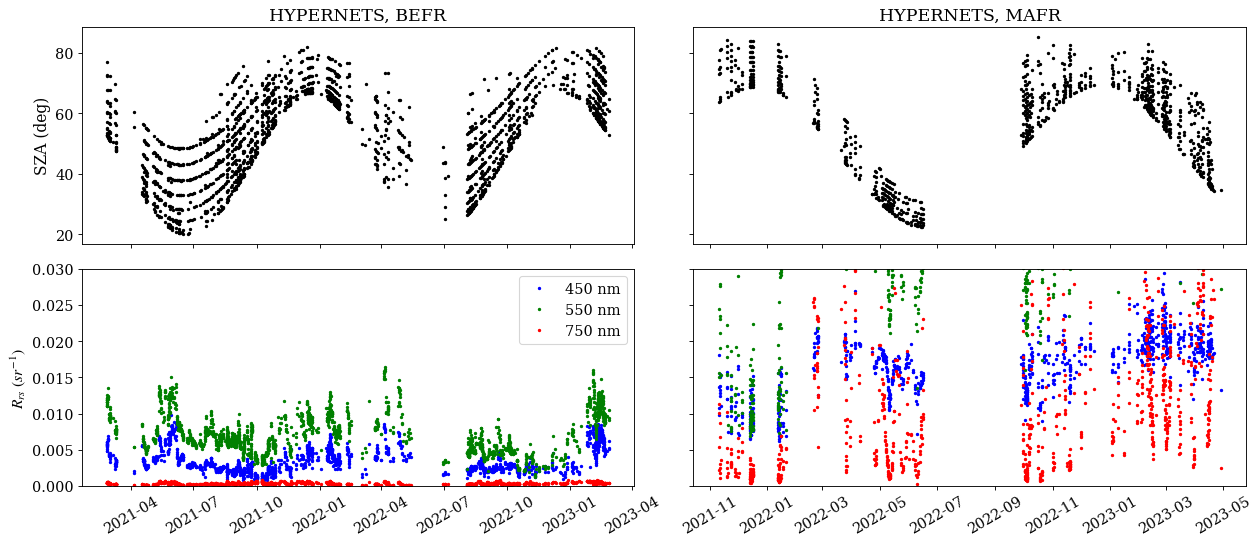

In [4]:
fig, axs = plt.subplots(nrows=2, ncols=len(STATIONS), figsize=(16, 7), sharex='col', sharey='row', squeeze=False)
for k, station in enumerate(STATIONS):
    hyp = hypernets.where(hypernets.site == station, drop=True)
    axs[0, k].plot(hyp.time.values, hyp.sza.values, 'o', ms=2, c='k')
    for wl, color in zip([450, 550, 750], ['blue', 'green', 'red']):
        axs[1, k].plot(hyp.time.values, hyp.Rrs.sel(wl=wl).values, 'o', ms=2, c=color, label=f'{wl} nm')
    axs[0, k].set_title(f'HYPERNETS, {station}')
    axs[1, k].tick_params(axis='x', labelrotation=30)
axs[0, 0].set_ylabel('SZA (deg)')
axs[1, 0].set_ylabel(r'$R_{rs}\ (sr^{-1})$')
axs[1, 0].set_ylim(0, 0.03)
axs[1, 0].legend()
fig.tight_layout()

Daily median (line) and 20-80 % percentiles (shaded) of the BEFR spectra over two weeks; the red bands mark the
O$_2$ absorption bands (687 and 760 nm), where the in situ spectra are noisier.

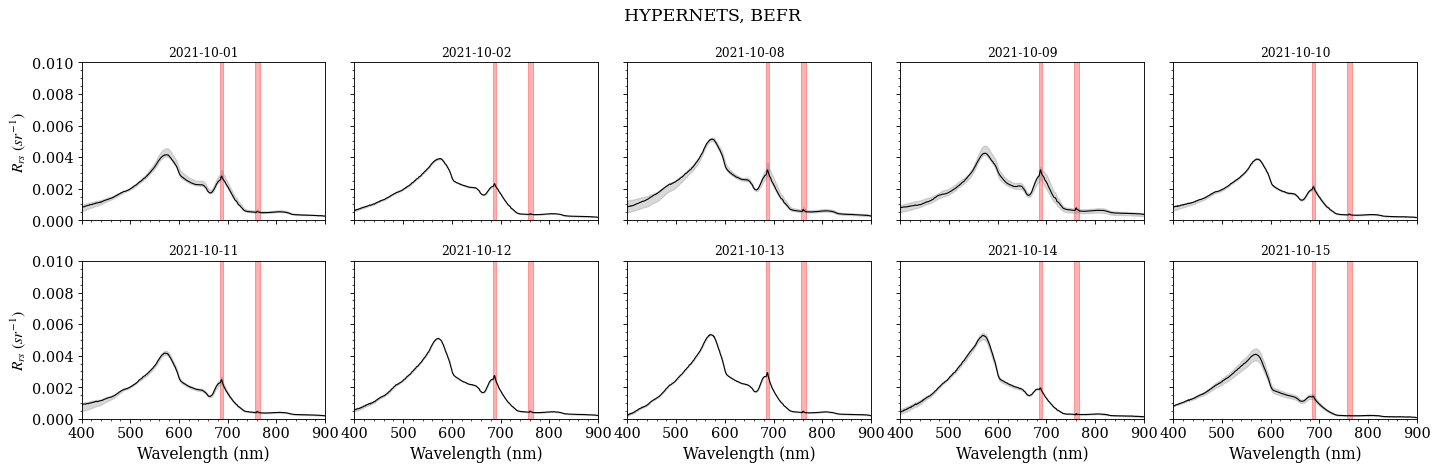

In [5]:
befr = hypernets.where(hypernets.site == 'BEFR', drop=True).swap_dims(obs='time')
period = befr.sel(time=slice('2021-10-01', '2021-10-15'))
days = np.unique(period.time.dt.floor('1D').values)

ncols = 5
nrows = int(np.ceil(len(days) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(ncols * 3.6, nrows * 3), sharex=True, sharey=True, squeeze=False)
for ax in axs.flat:
    ax.set_axis_off()
for ax, day in zip(axs.flat, days):
    Rrs = period.Rrs.sel(time=slice(day, day + np.timedelta64(1, 'D')))
    ax.set_axis_on()
    with warnings.catch_warnings():           # no in situ data beyond 900 nm
        warnings.simplefilter('ignore', RuntimeWarning)
        ax.fill_between(Rrs.wl, Rrs.quantile(0.2, 'time'), Rrs.quantile(0.8, 'time'), alpha=0.3, color='grey')
        ax.plot(Rrs.wl, Rrs.median('time'), c='k', lw=1)
    for wl_min, wl_max in [(684, 691), (757, 767)]:
        ax.axvspan(wl_min, wl_max, color='red', alpha=0.3, zorder=-6)
    ax.set_title(pd.Timestamp(day).strftime('%Y-%m-%d'), fontsize=11)
    ax.set_xlim(400, 900)
    ax.set_ylim(0, 0.01)
    ax.minorticks_on()
for ax in axs[:, 0]:
    ax.set_ylabel(r'$R_{rs}\ (sr^{-1})$')
for ax in axs[-1]:
    ax.set_xlabel('Wavelength (nm)')
fig.suptitle('HYPERNETS, BEFR')
fig.tight_layout()

## 2. Normalization to nadir viewing

HYPERNETS observes the water surface with an oblique viewing geometry (40° from nadir, 135° from the sun), while
Sentinel-2 views it close to nadir. Because of the anisotropy of the water-leaving radiance, the in situ $R_{rs}$
can be converted to nadir viewing with pre-computed factors depending on the solar zenith angle (`sza`) and
wavelength:

$$R_{rs}^{nadir}(\lambda) = f(\theta_s, \lambda)\, R_{rs}(\lambda)$$

The factors of `DIR_NORM_FILE` were computed for the nominal viewing geometry of the HYPERNETS stations with a
bio-optical model (see the `model` and `dataset` coordinates of the file); they are applied to both stations. They
are plotted below for three solar zenith angles. {func}`~grstbx.validation.read_hypernets` applies them
(`dir_norm`), giving the column `Rrs_insitu_nadir` of the matchup table next to `Rrs_insitu`, as measured.

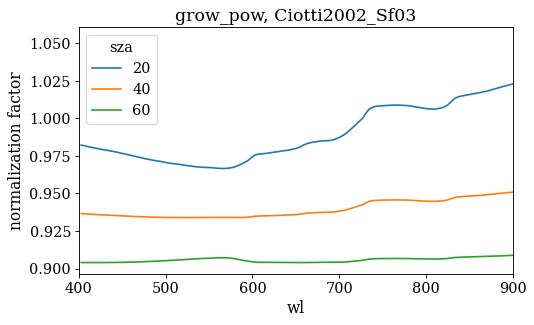

In [6]:
dir_norm = xr.open_dataarray(DIR_NORM_FILE).load()

fig, ax = plt.subplots(figsize=(7, 4))
dir_norm.sel(sza=[20, 40, 60]).plot(hue='sza', ax=ax)
ax.set_xlim(400, 900)
ax.set_ylabel('normalization factor')
ax.set_title(f"{dir_norm.model.values}, {dir_norm.dataset.values}");

## 3. Sentinel-2 subsets around the stations

GRS runs on subsets of 251 x 251 pixels at 20 m (about 5 km x 5 km) centred on the station, as for AERONET-OC:
about 25 s per image instead of several minutes for a tile, and the station falls in the central pixel, where
{func}`~grstbx.validation.extract_window` looks for it.

The subsets are cut from the GRSdriver L1C products of 25.6 km around the stations (`SOURCE_L1C`: bands at
20 m, viewing angles per band, sun angles, spectral response functions), for the images with a QC-approved
HYPERNETS measurement within `WINDOW_H` hours. They are written as
`ROOT/sentinel-2/l1c/<station>/YYYY/MM/DD/<name>_<station>.nc` (packed as the source); the ones already made are
kept.

In [7]:
def crop_subset(src, dst, lon, lat, half=HALF):
    # subset of 2 half + 1 pixels centred on (lon, lat); None if the station is too close to the edge
    with xr.open_dataset(src) as ds:
        x, y = Transformer.from_crs(4326, ds.rio.crs, always_xy=True).transform(lon, lat)
        ix, iy = int(np.abs(ds.x - x).argmin()), int(np.abs(ds.y - y).argmin())
        if min(ix, iy) < half or ix + half >= ds.sizes['x'] or iy + half >= ds.sizes['y']:
            return None
        sub = ds.isel(x=slice(ix - half, ix + half + 1), y=slice(iy - half, iy + half + 1))
        sub = sub.drop_vars(['surfwater', 'cloud_p06', 'cloud_p08'], errors='ignore').load()
    for var in sub.variables.values():           # same packing as the source, without its chunks
        var.encoding = {k: v for k, v in var.encoding.items()
                        if k in ('dtype', 'scale_factor', 'add_offset', '_FillValue', 'units', 'calendar')}
        if var.ndim >= 2:
            var.encoding.update(zlib=True, complevel=5)
    sub.attrs.update(subset_station=dst.stem.split('_')[-1], subset_lon=lon, subset_lat=lat,
                     subset_source=str(src))
    dst.parent.mkdir(parents=True, exist_ok=True)
    sub.to_netcdf(dst)
    return dst


def make_subsets(station, lon, lat, times, window_h=WINDOW_H):
    # 5 km subsets of the images of a station with an in situ measurement within window_h hours
    times = pd.DatetimeIndex(np.sort(times))
    rows = []
    for src in sorted(Path(SOURCE_L1C, station).glob('*/*.nc')):
        sat, _, date, *_ = src.stem.split('_')
        t = pd.Timestamp(date)
        lag = np.abs(times - t).min()
        if lag > pd.Timedelta(hours=window_h):
            continue
        dst = Path(ROOT, 'sentinel-2', 'l1c', station, f'{t:%Y}', f'{t:%m}', f'{t:%d}', f'{src.stem}_{station}.nc')
        if not dst.exists() and crop_subset(src, dst, lon, lat) is None:
            continue
        with xr.open_dataset(dst) as ds:
            time, cloud = pd.Timestamp(ds.time.values), float(ds.attrs.get('cloud_cover', np.nan))
        rows.append({'id': dst.stem, 'time': time, 'station': station, 'sites': [station], 'lon': lon, 'lat': lat,
                     'dt_min': lag.total_seconds() / 60, 'tile': src.stem.split('_')[5][1:],
                     'platform': f'sentinel-2{sat[-1].lower()}', 'cloud_cover': cloud, 'subset': str(dst)})
    return pd.DataFrame(rows)


items = pd.concat([make_subsets(st, row.lon, row.lat, hypernets.time.values[hypernets.site.values == st])
                   for st, row in stations.iterrows()], ignore_index=True)
items.groupby(['station', 'platform']).size().unstack()

platform,sentinel-2a,sentinel-2b
station,,
BEFR,46,57
MAFR,13,12


TOA reflectance of one subset (RGB) with the station (red cross) and the ring of the extraction window (4 to 7
pixels from the station):

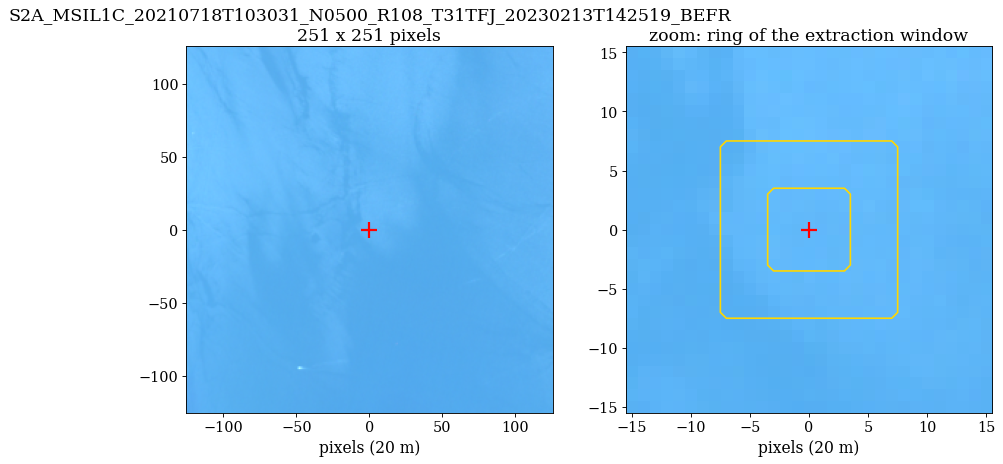

In [8]:
row = items[items.station == 'BEFR'].sort_values('cloud_cover').iloc[0]
with xr.open_dataset(row.subset) as ds:
    rgb = ds.bands.sel(wl=[665, 560, 490]).load()
ring = val.window_mask(rgb.sizes['y'], rgb.sizes['x'], 'ring', (4, 7))

fig, axs = plt.subplots(ncols=2, figsize=(13, 6))
for ax, zoom in zip(axs, [HALF, 15]):
    view = rgb.isel(x=slice(HALF - zoom, HALF + zoom + 1), y=slice(HALF - zoom, HALF + zoom + 1))
    img = (view / view.quantile(0.98)).clip(0, 1).transpose('y', 'x', 'wl')
    ax.imshow(img, extent=[-zoom - 0.5, zoom + 0.5, -zoom - 0.5, zoom + 0.5])
    ax.plot(0, 0, '+', c='red', ms=14, mew=2)
    ax.set_xlabel('pixels (20 m)')
r = ring.isel(x=slice(HALF - 15, HALF + 16), y=slice(HALF - 15, HALF + 16))
axs[1].contour(np.arange(-15, 16), np.arange(15, -16, -1), r.astype(int), levels=[0.5], colors='gold')
axs[0].set_title(f"{row.id}\n251 x 251 pixels")
axs[1].set_title('zoom: ring of the extraction window');

## 4. GRS on the subsets

{func}`~grstbx.validation.process_subsets` runs GRS on the subsets without L2A product, `WORKERS` images at a time,
one process per image, with the CAMS file of the day (or of the month). The L2A products are written as
`ROOT/sentinel-2/l2a/<station>/YYYY/MM/DD/<name>/<name>.nc` with their STAC Item; the images without enough water
get a `_no_water.txt` marker, the failures an `.err` file (run again with `retry_failed=True`). The cell can be run
again at any time: only the missing products are computed.

In [9]:
runs = val.process_subsets(items, root=ROOT, workers=WORKERS, verbose=False)
runs.state.value_counts()

state
done        117
no_water     11
Name: count, dtype: int64

## 5. Matchups

{func}`~grstbx.validation.matchup_table` extracts the statistics of the valid water pixels of each L2A product in
the ring around the station (without the station and its shadow, 4 to 7 pixels from it: 176 pixels), and pairs each
image with the nearest HYPERNETS spectrum within `MAX_LAG`.

The HYPERNETS spectra are hyperspectral: {func}`~grstbx.validation.read_hypernets` convolves them with the
spectral response functions (SRF) of the Sentinel-2 bands, taken from the subsets (variable `SRF`, average of S2A
and S2B), instead of an interpolation at the nominal wavelengths. The bands beyond 900 nm, where the in situ spectra
stop, are left out.

In [10]:
srf = xr.concat([val.band_srf(items[items.platform == p].subset.iloc[0]) for p in sorted(items.platform.unique())],
                dim='platform').mean('platform')
reader = functools.partial(val.read_hypernets, path=HYPERNETS, srf=srf, dir_norm=dir_norm)

table = val.matchup_table(items, root=ROOT, reader=reader, max_lag=MAX_LAG, verbose=False)
val.save_table(table, Path(ROOT, 'matchups', f'hypernets_grs_{grs.__version__}.csv'))

good = val.quality(table, **QC)
print(f'{table.image.nunique()} images with an L2A product and an in situ spectrum within {MAX_LAG}, '
      f'{table[good].image.nunique()} meeting the quality criteria ({good.sum()} matchups image x band)')
table[good].head()

117 images with an L2A product and an in situ spectrum within 2h, 54 meeting the quality criteria (486 matchups image x band)


,station,image,time,wl,wl_insitu,Rrs_sat,Rrs_sat_std,Rrs_insitu,residual,level,...,sza,vza,raa,sza_insitu,vza_insitu,raa_insitu,wind_insitu,aot550_insitu,Rrs_sat_mean,Rrs_insitu_nadir
0,BEFR,S2A_MSIL2AGRS_20210228T103021_N0500_R108_T31TF...,2021-02-28 10:30:21,443,443,0.003720,0.000173,0.003807,-0.000087,qc0,...,53.86,5.49,294.16,54.2052,40.000801,90.001999,5.168071,NaN,0.003709,0.003475
1,BEFR,S2A_MSIL2AGRS_20210228T103021_N0500_R108_T31TF...,2021-02-28 10:30:21,490,490,0.005275,0.000245,0.006379,-0.001104,qc0,...,53.86,5.49,294.16,54.2052,40.000801,90.001999,5.168071,NaN,0.005258,0.005826
2,BEFR,S2A_MSIL2AGRS_20210228T103021_N0500_R108_T31TF...,2021-02-28 10:30:21,560,560,0.007605,0.000219,0.009634,-0.002029,qc0,...,53.86,5.49,294.16,54.2052,40.000801,90.001999,5.168071,NaN,0.007621,0.008811
3,BEFR,S2A_MSIL2AGRS_20210228T103021_N0500_R108_T31TF...,2021-02-28 10:30:21,665,665,0.001530,0.000205,0.002167,-0.000637,qc0,...,53.86,5.49,294.16,54.2052,40.000801,90.001999,5.168071,NaN,0.001514,0.001979
4,BEFR,S2A_MSIL2AGRS_20210228T103021_N0500_R108_T31TF...,2021-02-28 10:30:21,705,705,0.001380,0.000297,0.001431,-0.000051,qc0,...,53.86,5.49,294.16,54.2052,40.000801,90.001999,5.168071,NaN,0.001355,0.001308


Quality criteria of the images: lag between the in situ and satellite measurements, proportion of valid pixels in
the ring and coefficient of variation of $R_{rs}(560)$; the images meeting all the criteria are in colour.

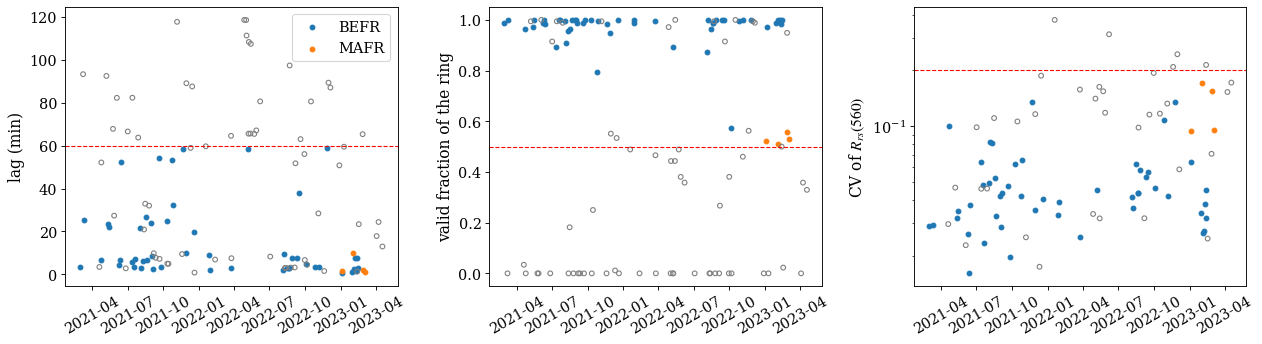

In [11]:
images = table.drop_duplicates('image').set_index('image')
ok = good.groupby(table.image).first().reindex(images.index)

fig, axs = plt.subplots(ncols=3, figsize=(16, 4.5))
for ax, col, limit, label in [(axs[0], 'lag_min', QC['max_lag_min'], 'lag (min)'),
                              (axs[1], 'frac_valid', QC['min_valid'], 'valid fraction of the ring'),
                              (axs[2], 'cv560', QC['max_cv'], r'CV of $R_{rs}(560)$')]:
    values = images[col].abs() if col == 'lag_min' else images[col]
    for station, color in zip(STATIONS, ['tab:blue', 'tab:orange']):
        sel = images.station == station
        ax.scatter(images.time[sel & ok], values[sel & ok], s=18, c=color, label=station)
        ax.scatter(images.time[sel & ~ok], values[sel & ~ok], s=18, facecolors='none', edgecolors='grey')
    ax.axhline(limit, c='red', ls='--', lw=1)
    ax.set_ylabel(label)
    ax.tick_params(axis='x', labelrotation=30)
axs[2].set_yscale('log')
axs[0].legend()
fig.tight_layout()

Spectra of the matchups meeting the quality criteria: HYPERNETS spectrum paired with the image (blue: as measured,
green: normalized to nadir; dots: convolved with the SRF), GRS median (black) and standard deviation (grey) in the
ring, with an RGB thumbnail of the L2A product around the station.

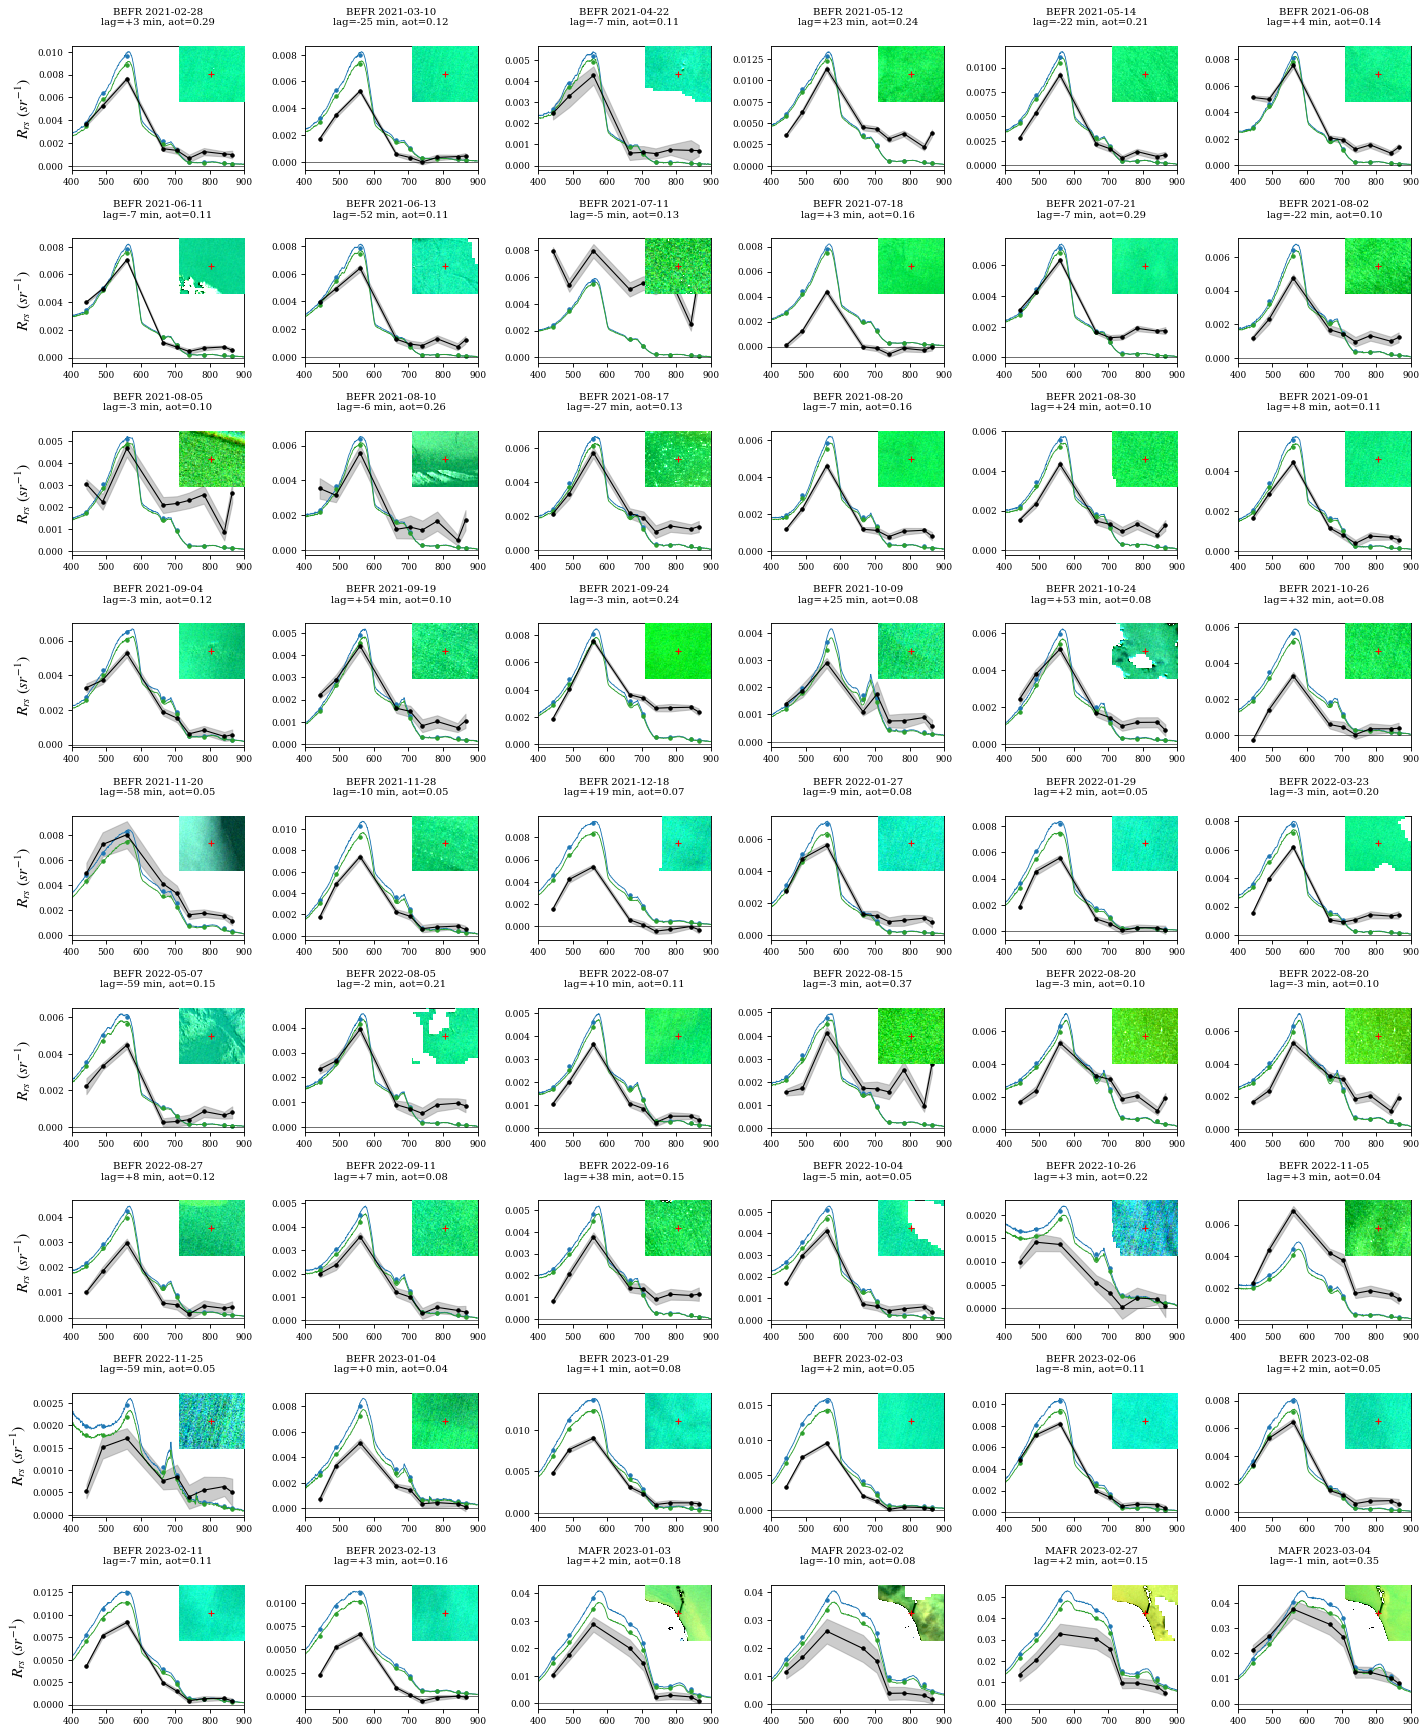

In [12]:
sel = table[good]
paired = sel.drop_duplicates('image').sort_values(['station', 'time'])
hyp = {st: hypernets.where(hypernets.site == st, drop=True).swap_dims(obs='time') for st in STATIONS}

ncols = 6
nrows = int(np.ceil(len(paired) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(ncols * 3.6, nrows * 3.), squeeze=False)
fig.subplots_adjust(hspace=0.55, wspace=0.35)
for ax in axs.flat:
    ax.set_axis_off()
for ax, m in zip(axs.flat, paired.itertuples()):
    bands = sel[sel.image == m.image]
    spectrum = hyp[m.station].Rrs.sel(time=m.time_insitu)
    nadir = dir_norm.interp(wl=spectrum.wl).interp(sza=float(m.sza_insitu)) * spectrum
    ax.set_axis_on()
    ax.plot(spectrum.wl, spectrum, c='tab:blue', lw=0.8)
    ax.plot(nadir.wl, nadir, c='tab:green', lw=0.8)
    ax.plot(bands.wl, bands.Rrs_insitu, 'o', c='tab:blue', ms=3)
    ax.plot(bands.wl, bands.Rrs_insitu_nadir, 'o', c='tab:green', ms=3)
    ax.fill_between(bands.wl, bands.Rrs_sat - bands.Rrs_sat_std, bands.Rrs_sat + bands.Rrs_sat_std,
                    color='grey', alpha=0.4)
    ax.plot(bands.wl, bands.Rrs_sat, 'o-', c='k', ms=3, lw=1)
    ax.axhline(0, c='k', lw=0.5)
    ax.set_xlim(400, 900)
    ax.set_title(f"{m.station} {m.time:%Y-%m-%d}\nlag={m.lag_min:+.0f} min, aot={m.aot550_sat:.2f}", fontsize=9)
    ax.tick_params(labelsize=8)

    inset = ax.inset_axes([0.62, 0.55, 0.38, 0.45])
    with xr.open_dataset(m.l2a) as l2a:
        rgb = l2a.Rrs.sel(wl=[665, 560, 490]).isel(x=slice(HALF - 30, HALF + 31), y=slice(HALF - 30, HALF + 31))
        rgb = rgb.where(l2a['mask'].isel(x=slice(HALF - 30, HALF + 31), y=slice(HALF - 30, HALF + 31)) == 0).load()
    rgb.plot.imshow(ax=inset, rgb='wl', robust=True)
    inset.plot(rgb.x[30], rgb.y[30], '+', c='red', ms=6)
    inset.set_axis_off()
    inset.set_title('')
for ax in axs[:, 0]:
    ax.set_ylabel(r'$R_{rs}\ (sr^{-1})$')

## 6. Agreement statistics

{func}`~grstbx.validation.metrics_table` computes the statistics of the matchups ({func}`~grstbx.matchup.matchup_metrics`),
overall and by group: slope, intercept and Pearson's r of the linear regression, rmse and bias, mean absolute
percentage error (mape), median symmetric accuracy ($\epsilon$, MdSA) and signed symmetric percentage bias
($\beta$, SSPB), and their log-space counterparts.

By band, in situ $R_{rs}$ as measured and normalized to nadir:

In [13]:
columns = ['N', 'slope', 'intercept', 'r', 'rmse', 'bias', 'mape', 'eps', 'beta']
metrics = pd.concat({'as measured': val.metrics_table(table[good], by='wl')[columns],
                     'at nadir': val.metrics_table(table[good], by='wl', x='Rrs_insitu_nadir')[columns]}, axis=1)
metrics.round(4)

as measured                                                                \
              N   slope intercept       r    rmse    bias      mape       eps   
wl                                                                              
all         486  0.7033    0.0005  0.9611  0.0024 -0.0005  175.4104   65.2053   
443          54  0.7093    0.0002  0.8543  0.0025 -0.0011   41.4161   60.6810   
490          54  0.7225    0.0003  0.9512  0.0027 -0.0015   25.3471   34.1376   
560          54  0.7377    0.0004  0.9764  0.0036 -0.0021   22.7822   26.4067   
665          54  0.7040    0.0002  0.9850  0.0032 -0.0012   38.5719   42.2356   
705          54  0.6925    0.0004  0.9782  0.0026 -0.0006   47.3702   33.7815   
740          54  0.6050    0.0006  0.8607  0.0017  0.0001  205.7007  156.2965   
783          54  0.6367    0.0009  0.8461  0.0016  0.0005  304.5181  218.9719   
842          54  0.6376    0.0007  0.8974  0.0012  0.0003  277.2634  209.5838   
865          54  0.5776    0.0009  0.6169  0.0015  0.0006  615.7240  335.9783   

              at nadir                                                      \
         beta        N   slope intercept       r    rmse    bias      mape   
wl                                                                           
all   -4.0196      486  0.7763    0.0005  0.9621  0.0019 -0.0002  182.3606   
443  -57.1376       54  0.7907    0.0001  0.8573  0.0021 -0.0007   40.8624   
490  -32.2120       54  0.8026    0.0002  0.9518  0.0021 -0.0010   22.0145   
560  -25.6212       54  0.8176    0.0003  0.9776  0.0025 -0.0013   17.6862   
665  -41.6527       54  0.7796    0.0001  0.9859  0.0023 -0.0008   36.3469   
705  -11.6839       54  0.7659    0.0004  0.9793  0.0020 -0.0003   48.7222   
740  102.6545       54  0.6677    0.0006  0.8640  0.0015  0.0002  216.8208   
783  218.9719       54  0.7026    0.0009  0.8494  0.0015  0.0006  321.7649   
842  209.5838       54  0.7029    0.0007  0.9004  0.0011  0.0004  295.2653   
865  335.9783       54  0.6383    0.0009  0.6214  0.0015  0.0007  641.7618   

                         
          eps      beta  
wl                       
all   55.0548    3.4768  
443   50.7093  -41.3057  
490   24.3437  -20.8424  
560   17.0178  -16.2121  
665   33.4957  -30.6087  
705   30.1076   -3.8907  
740  165.9657  121.7127  
783  232.5008  232.5008  
842  247.2263  247.2263  
865  352.4819  352.4819

By station, in situ $R_{rs}$ normalized to nadir:

In [14]:
val.metrics_table(table[good], by='station', x='Rrs_insitu_nadir')[columns].round(4)

,N,slope,intercept,r,rmse,bias,mape,eps,beta
station,,,,,,,,,
all,486,0.7763,0.0005,0.9621,0.0019,-0.0002,182.3606,55.0548,3.4768
BEFR,450,0.7032,0.0007,0.8598,0.0013,0.0000,194.6060,62.1013,11.1144
MAFR,36,0.8387,-0.0009,0.9560,0.0053,-0.0039,29.2924,34.5792,-34.5792


Per band, with the in situ $R_{rs}$ normalized to nadir viewing (error bars: standard deviation of GRS in the ring):

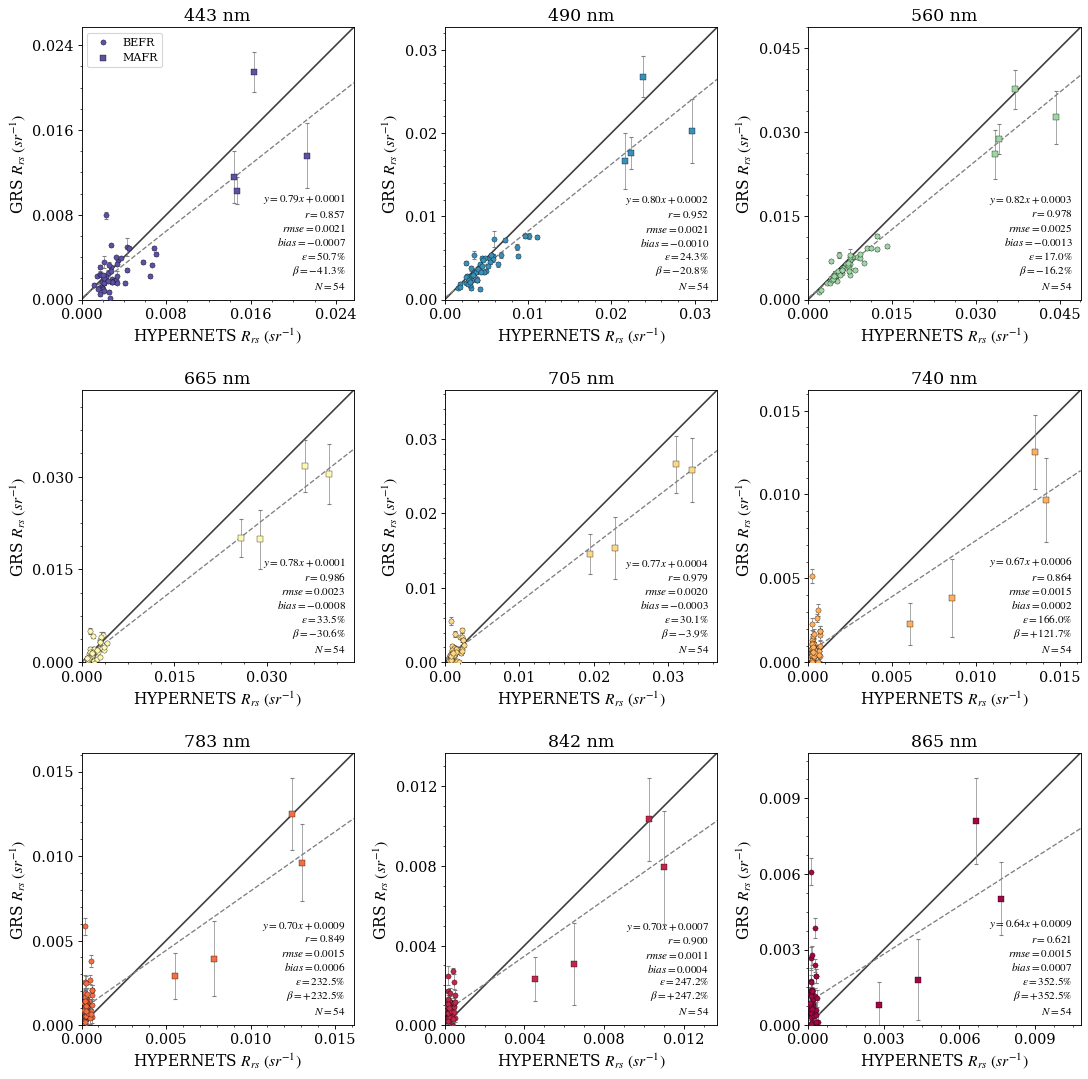

In [15]:
cmap = plt.cm.Spectral_r
norm = mpl.colors.Normalize(vmin=440, vmax=870)
markers = dict(zip(STATIONS, ['o', 's']))

wls = sorted(table[good].wl.unique())
ncols = 3
nrows = int(np.ceil(len(wls) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(ncols * 4.6, nrows * 4.6), squeeze=False)
for ax in axs.flat:
    ax.set_axis_off()
for ax, wl in zip(axs.flat, wls):
    m = table[good & (table.wl == wl)]
    ax.set_axis_on()
    vmax_band = 1.1 * float(max(m.Rrs_insitu_nadir.max(), (m.Rrs_sat + m.Rrs_sat_std).max()))
    plot_matchup(ax, m.Rrs_insitu_nadir, m.Rrs_sat, 0, vmax_band, yerr=m.Rrs_sat_std, s=0)
    for station, marker in markers.items():
        s = m[m.station == station]
        ax.scatter(s.Rrs_insitu_nadir, s.Rrs_sat, marker=marker, color=cmap(norm(wl)), edgecolors='k',
                   linewidths=0.3, s=22, zorder=3, label=station)
    ax.set_title(f'{wl} nm')
    ax.set_xlabel(r'HYPERNETS $R_{rs}\ (sr^{-1})$')
    ax.set_ylabel(r'GRS $R_{rs}\ (sr^{-1})$')
axs.flat[0].legend(loc='upper left', fontsize=10)
fig.tight_layout()

All bands, before and after the normalization of the in situ data to nadir viewing:

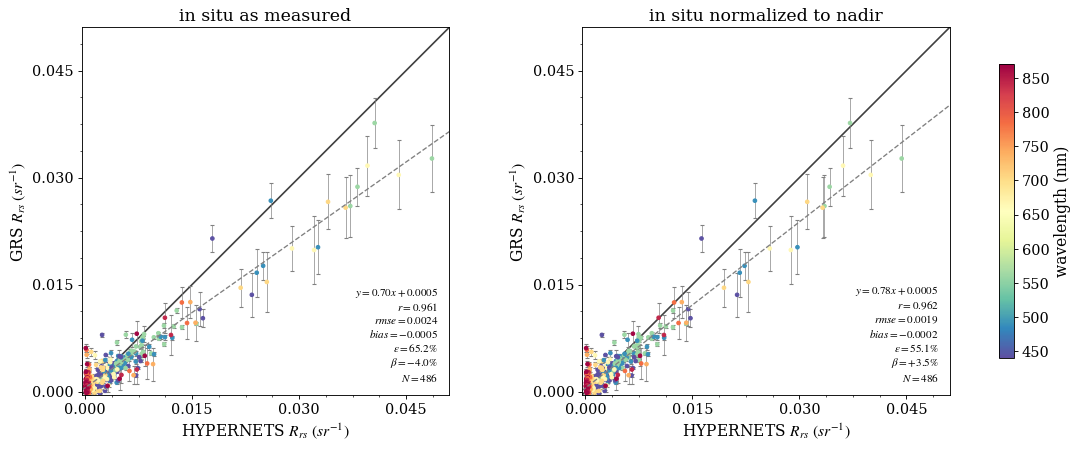

In [16]:
df = table[good]
vmax = 1.05 * float(max(df.Rrs_insitu.max(), df.Rrs_sat.max()))

fig, axs = plt.subplots(ncols=2, figsize=(14, 5.5), layout='constrained')
for ax, insitu_var, title in zip(axs, ['Rrs_insitu', 'Rrs_insitu_nadir'],
                                 ['in situ as measured', 'in situ normalized to nadir']):
    sc, _ = plot_matchup(ax, df[insitu_var], df.Rrs_sat, -0.0005, vmax, yerr=df.Rrs_sat_std,
                         c=df.wl, cmap=cmap, norm=norm, s=10)
    ax.set_xlabel(r'HYPERNETS $R_{rs}\ (sr^{-1})$')
    ax.set_ylabel(r'GRS $R_{rs}\ (sr^{-1})$')
    ax.set_title(title)
fig.colorbar(sc, ax=axs, shrink=0.8, label='wavelength (nm)');

## 7. Dashboard

The table can be explored interactively with the dashboard of the AERONET-OC validation
({func}`~grstbx.validation.dashboard`, see {doc}`../aeronet_oc_validation`): quality criteria and selections
(stations, bands, in situ normalization, period, platforms), scatter plots per band, statistics and heat map,
residuals, spectra with the quicklooks of the L2A products, time series and drivers of the residuals. With
HYPERNETS, the in situ choices and the network name are given to the dashboard. It needs a running Python kernel
(not rendered in this page): run the cell in Jupyter.

```python
val.dashboard(table, title='GRS L2A vs HYPERNETS', network='HYPERNETS',
              insitu={'HYPERNETS (as measured)': 'Rrs_insitu', 'HYPERNETS at nadir': 'Rrs_insitu_nadir'})
```

## Notes and references

- The subsets are cut from GRSdriver L1C products: they hold the same pixels and angles as the L1C tiles, at 20 m.
- The SRF are the average of those of S2A and S2B: their nominal wavelengths differ by less than 1 nm except at
  783 nm (2-3 nm), with a negligible effect on the band-averaged $R_{rs}$ of water.
- The normalization factors to nadir viewing were computed for the nominal HYPERNETS geometry with a bio-optical
  model; they are applied to both stations, and the effect on the statistics is shown above.
- The extraction ring (4 to 7 pixels, 80-140 m, from the station) excludes the station, its shadow and the pixels
  much brighter than the ring at 865 nm (boats, structures).
- The $\epsilon$ and $\beta$ metrics are less sensitive to outliers than rmse and bias; they are computed in log
  space and expressed in %.

**References**

- Bailey, S. W., & Werdell, P. J. (2006). A multi-sensor approach for the on-orbit validation of ocean color
  satellite data products. *Remote Sensing of Environment*, 102, 12-23.
- Morley, S. K., Brito, T. V., & Welling, D. T. (2018). Measures of model performance based on the log accuracy
  ratio. *Space Weather*, 16, 69-88.
- Pahlevan, N., et al. (2020). Seamless retrievals of chlorophyll-a from Sentinel-2 (MSI) and Sentinel-3 (OLCI)
  in inland and coastal waters: a machine-learning approach. *Remote Sensing of Environment*, 240, 111604.
- Ruddick, K. G., et al. (2006). Seaborne measurements of near infrared water-leaving reflectance: the similarity
  spectrum for turbid waters. *Limnology and Oceanography*, 51(2), 1167-1179.
- Ruddick, K. G., et al. (2024). WATERHYPERNET: a prototype network of automated in situ measurements of
  hyperspectral water reflectance for satellite validation and water quality monitoring. *Frontiers in Remote
  Sensing*, 5, 1347520.